In [13]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph
import math

In [14]:
class AgentState(TypedDict):
  name: str
  operation: str
  values: list[int]
  result: str

In [27]:
def Operation_node(state: AgentState) -> AgentState:
  """ Simple function that perfoms the Arithematic functions on the values"""

  if state["operation"] == "sum":
    state["result"] = "Hey "+ state["name"]+ ", the sum of values is: "+str(sum(state["values"]))
    return state
  
  elif state["operation"] == "prod":
    state["result"] = "Hey "+ state["name"]+", the product is :"+ str(math.prod(state["values"]))
    return state

  else:
    state["result"] = "Hey "+ state["name"]+", Your Operator is invalid! Try again with another operator"
    return state


In [28]:
graph = StateGraph(AgentState)
graph.add_node("Operator", Operation_node)
graph.set_entry_point("Operator")
graph.set_finish_point("Operator")

app = graph.compile()

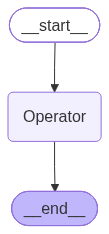

In [29]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [31]:
result = app.invoke({"name":"Bob", "operation":"sum", "values":[1,2,3]})
print(result)
print(result["result"])

{'name': 'Bob', 'operation': 'sum', 'values': [1, 2, 3], 'result': 'Hey Bob, the sum of values is: 6'}
Hey Bob, the sum of values is: 6


In [32]:
result = app.invoke({"name":"Alice", "operation":"prod", "values":[1,2,3]})
print(result)
print(result["result"])

{'name': 'Alice', 'operation': 'prod', 'values': [1, 2, 3], 'result': 'Hey Alice, the product is :6'}
Hey Alice, the product is :6


In [33]:
result = app.invoke({"name":"Charlie", "operation":"any", "values":[1,2,3]})
print(result)
print(result["result"])

{'name': 'Charlie', 'operation': 'any', 'values': [1, 2, 3], 'result': 'Hey Charlie, Your Operator is invalid! Try again with another operator'}
Hey Charlie, Your Operator is invalid! Try again with another operator
